# Part B: Flow Matching from Scratch!
Student notebook: implement the marked exercises using [the assignment](partb.html).


**Conventions:** MNIST pixels are in $[0,1]$. Flow time goes from Gaussian noise
at 0 to data at 1. Predict velocity $x_1-x_0$, not noise. Part B uses
$v_u+\gamma(v_c-v_u)$ with $\gamma=5$; this is different from Part A's guidance convention.

## Start here
1. Select a **GPU**: Colab **Runtime → Change runtime type**, or Kaggle **Settings → Accelerator**. Enable Internet on Kaggle.
2. Run the **Setup** cell below. Everything needed is included or downloaded automatically.
3. Complete the exercises below and run their cells.

**No ZIP upload, Google Drive mount, helper-file edits, or cache configuration is needed.**
Use a fresh runtime when switching between Part A and Part B. Downloads are automatically
reused within the session. Save your notebook with outputs before disconnecting.

In [ ]:
#@title Setup (run once)
# Supplied support code and images are embedded: no separate files are needed.
import os, sys, time, io, base64, zipfile, hashlib
from pathlib import Path
_cs180_started = time.perf_counter()
IN_COLAB = 'google.colab' in sys.modules
IN_KAGGLE = Path('/kaggle/working').is_dir()
PART = 'partb'
_work = Path('/content/cs180-hw3') if IN_COLAB else (Path('/kaggle/working') if IN_KAGGLE else Path.cwd())
_work.mkdir(parents=True,exist_ok=True)
_support = base64.b64decode('UEsDBBQAAAAIAAAAIVx0NVtTYAUAACkNAAAOAAAAY29sYWJfc2V0dXAucHm1V11T3DYUfd9foZIH2YkRENI23Yk7QwlJmBSyA6QvDOPR2nd3VWzJleSFLcN/75VkG8MCaTPTfVivdaVzv8/VbmxsHFxD3lgoyHRFpLIwVeqSGLBNTfjMgibG8rmQc2IXQExT10pbMm1kUQIpVc7LcsU2NjZGovKS8CjFlFVgecEt7yTKjGZaVaTmdoHydieZ4Gu3xTTTWqscjOlXVmY0yjSgEdri869GaLQ1JecXo9GogBkREmVlmVXCGDQzuuISvYnHI4IfNOwwyMlMaGMT54UkDgchCSctMlGyXJGZ0ugSL1BBzfNLPgeD+7kl+YLLORTeTwc7L9WUl2TNLi8Us3VBsMZ9NBcGyEkjrajgQGulIzrplF2BBtLUGDU0QUhULgxpI8LISWurS8S+KvkU04Q+K0loD//Ih04BHQN0VTdSukz67I4JfUUTQtmfSshozeI49phtxpx9eJKZGnIxE6BNl77TbuUUrD/R5iHFBHkAjGkbzMSddm6FFDFhoTJRfBcbq1djskRw9CldLyTWiqIWL+4PwnUO9WO1x9rQHiv7QWHN+oDf6ThWEnoQzFu7TjDqTkTQ9m4JW8OZPnQ3cv7E485jxusaZNFZ98pLu4pwx9t9g1rAPGjpX1+QQ5mXTQEYBC6NsGIJpAAHCDIXWBsRsDkjVl2CFH+jUXHiQRupoQz14r3HH5UqmhIM88ChnjOtlDXpjeQVYBJLYSPKaHy+feET5Jadd9htrD1960+H0klvbvtcBnHS9weeeiTsnTgrhLFaTBuLMcRcr+ccYxMguwgPDR6TXGGjyOYuS4N6crs7ReN7HeALKdh+3u64+E8F9T1FVXOkLXew1kJifFvicQ3X81Zvruu8vvnawmhb7o4EWb6A/DJzHBudu9yA52o+xQTQzYomtBY1frcUiL82N1ERWJq8bDEv2grsnRByyUvhGAZxER+TsdanqvTsEwL4RJtKuPpfW9ThP2xPXCM/pATNG69T7IP2i7+Ti9uscVewWH1VXQL2VIITzxMv7uelBl6sNh9OinZIjJ9n42c59xV9juWVzCH5BteH8dbIboLPuZCMnC2gm5NDi68EzsWpmwyNwQDSuB2p2HQzMW80YDA1zsxuxA75KP3ASwNtVbhmTd0gZ/lV0RaUry6/GCmsXLkUWkmGZqEG3pTYIPunO2+3s/29/U8H2fvDE5ogVUQOaosyf5rG8QCLVZeF0M4kkMhlZ7qBBK6RXzJ16d/C3ieUffqQffpydBCUeLwtumjmbqrNeO5UPXc6mDo5+XI0OQsW3wPCfq1qm0E1haJARPOv4M5O9g6PH0HDCSDcnP4GyORw8jB4nTnICnHfAI9l764HXpDPAHWoNGrI/tf3e5uu7LEBkGZw3uh8seW/lyLMxmGDINHx3LIeLUz29IZW3Nalco1Ox/TXdJf9nLx7gwQ1wZJTV37tF/aa3g7b2xVbmlL34PQ+obc3hnA1im6oH5LIThXSDYKl6Rv24w7bRQWDnG4umqkXbrPdn1BZQkFIVRuvfZu9Td7t0Ns7hnriIjngzxCNtYUQmOGk98ssbwrOhMn4kovSkfaQRB/jnlMoIXe30o+Tr4TnOb5qjliOjAMV4O/PfD5H/u8usn2vu/Z1wFiLtUkHFszBYu6XIofMyUBbLIBoOx7OKlSII8kfZe4ykNA/TvaOyEfxGy5rR8tREFqFMcoqqJRebb1++XJ3O9mJ70FNVmdON54LNmRZOxOyLKGDeHUbwttw2z24391fjEAAeMI/+8p+omA6QxyL7uEb3ti8QjJDyra7r0lk4doS7ARV4P8bLt3dyd0n8CICZdwFMtzOgurRP1BLAQIUAxQAAAAIAAAAIVx0NVtTYAUAACkNAAAOAAAAAAAAAAAAAACAAQAAAABjb2xhYl9zZXR1cC5weVBLBQYAAAAAAQABADwAAACMBQAAAAA=')
assert hashlib.sha256(_support).hexdigest() == 'ba2fae2d7267a416d94cd581fd0ac5eadf93d641618063a782d0dffdc36d31cd', 'Damaged notebook support data'
with zipfile.ZipFile(io.BytesIO(_support)) as _archive:
    for _entry in _archive.infolist():
        _target=(_work/_entry.filename).resolve()
        if _work.resolve() not in _target.parents: raise ValueError('Unsafe embedded path')
    _archive.extractall(_work)
os.chdir(_work)
if str(_work) not in sys.path: sys.path.insert(0,str(_work))
from colab_setup import configure
configure(PART,install_dependencies=IN_COLAB or IN_KAGGLE)
print('Setup complete. Continue with the notebook below.')

GPU: NVIDIA A100-SXM4-40GB VRAM GiB: 39.5
PyTorch: 2.11.0+cu130 torchvision: 0.26.0+cu130
Local cache: /content/cs180-hw3/.cache
Setup complete. Continue with the notebook below.


## Setup environment

In [ ]:
# Install requirements-partb.txt in the active environment before running.
# No automatic package changes to an existing GPU environment.
import sys
assert sys.version_info >= (3,9), 'Use Python 3.9 or newer.'

In [ ]:
import os, json, time, random
from pathlib import Path
from typing import Optional
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torchvision.datasets import MNIST
from torchvision.transforms import ToTensor
from torchvision.utils import make_grid
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

SEED = 180
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(4)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
GROUP = os.environ.get('PARTB_GROUP','all')
assert GROUP in ('all','denoise','time','class','no_scheduler')
OUT = Path('out')
OUT.mkdir(parents=True, exist_ok=True)
metrics = {'seed':SEED,'group':GROUP,'torch':torch.__version__,
           'device':str(device),'gpu':torch.cuda.get_device_name() if device.type=='cuda' else None,
           'visible_devices':os.environ.get('CUDA_VISIBLE_DEVICES'),
           'precision':'float32 with TF32 convolution/matmul enabled'}
print(metrics)
train_dataset = MNIST('data', train=True, download=True, transform=ToTensor())
test_dataset = MNIST('data', train=False, download=True, transform=ToTensor())
assert len(train_dataset)==60000 and len(test_dataset)==10000

def show_grid(images, title, filename, nrow=10):
    images = images.detach().float().cpu()
    grid = make_grid(images.clamp(0, 1), nrow=nrow, padding=2)
    fig, ax = plt.subplots(figsize=(12, max(2, len(images)/nrow*1.15)))
    ax.imshow(grid.permute(1, 2, 0)); ax.set_title(title); ax.axis('off')
    fig.tight_layout(); fig.savefig(OUT / filename, dpi=120)
    plt.show(); plt.close(fig)


def loss_plot(losses, name):
    fig, ax = plt.subplots(figsize=(8, 3))
    ax.plot(losses, alpha=.4, linewidth=.5)
    window = min(100, len(losses))
    smooth = torch.tensor(losses).unfold(0, window, 1).mean(1)
    ax.plot(range(window-1, len(losses)), smooth, linewidth=1)
    ax.set(xlabel='Optimizer step', ylabel='Mean squared error', title=name)
    fig.tight_layout(); fig.savefig(OUT / (name+'_loss.png'), dpi=120)
    plt.show(); plt.close(fig)


def make_loader(batch_size, seed=180):
    # Decode/normalize once; augmentation noise is still drawn fresh in each step.
    dataset = torch.utils.data.TensorDataset(train_dataset.data[:, None].float()/255,
                                             train_dataset.targets)
    return DataLoader(dataset, batch_size=batch_size, shuffle=True, num_workers=0,
                      pin_memory=device.type == 'cuda',
                      generator=torch.Generator().manual_seed(seed))

{'seed': 180, 'group': 'all', 'torch': '2.11.0+cu130', 'device': 'cuda', 'gpu': 'NVIDIA A100-SXM4-40GB', 'visible_devices': None, 'precision': 'float32 with TF32 convolution/matmul enabled'}


100%|██████████| 9.91M/9.91M [00:01<00:00, 5.74MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 134kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.26MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.09MB/s]


## Neural Network Resources

In this part, you will build and train a [UNet](https://arxiv.org/abs/1505.04597), which is more complex than the MLP you implemented in the NeRF project.  We provide all class definitions you may need (but feel free to add or modify them as necessary).  

Instead of asking ChatGPT to write everything for you, please consult the following resources when you get stuck — they will help you understand how and why things work under the hood.

- PyTorch Documentation — [`Conv2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html), [`ConvTranspose2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.ConvTranspose2d.html), and [`AvgPool2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.AvgPool2d.html).
- PyTorch Documentation - [`torchvision.datasets.MNIST`](https://docs.pytorch.org/vision/main/generated/torchvision.datasets.MNIST.html), the dataset we gonna use, and [`torch.utils.data.DataLoader`](https://docs.pytorch.org/docs/stable/data.html), the off-the-shell dataloader we can directly use.
- PyTorch [tutorial](https://docs.pytorch.org/tutorials/beginner/blitz/cifar10_tutorial.html) on how to train a classifier on CIFAR10 dataset. The structure of your training code will be very similar to this one.

# Part 1: Training a Single-step Denoising UNet


# Part 1.1: Implementing the UNet

## Implementing Simple and Composed Ops

In [ ]:
class Conv(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, 1, 1),
            nn.BatchNorm2d(out_channels), nn.GELU())
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.layers(x)
        # ===== end of code ====


class DownConv(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, 2, 1),
            nn.BatchNorm2d(out_channels), nn.GELU())
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.layers(x)
        # ===== end of code ====


class UpConv(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.layers = nn.Sequential(
            nn.ConvTranspose2d(in_channels, out_channels, 4, 2, 1),
            nn.BatchNorm2d(out_channels), nn.GELU())
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.layers(x)
        # ===== end of code ====


class Flatten(nn.Module):
    def __init__(self):
        super().__init__()
        # ===== your code here! ====
        self.layers = nn.Sequential(nn.AvgPool2d(7), nn.GELU())
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.layers(x)
        # ===== end of code ====


class Unflatten(nn.Module):
    def __init__(self, in_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.layers = nn.Sequential(
            nn.ConvTranspose2d(in_channels, in_channels, 7, 7, 0),
            nn.BatchNorm2d(in_channels), nn.GELU())
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.layers(x)
        # ===== end of code ====


class ConvBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.layers = nn.Sequential(Conv(in_channels, out_channels), Conv(out_channels, out_channels))
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.layers(x)
        # ===== end of code ====


class DownBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.layers = nn.Sequential(DownConv(in_channels, out_channels), ConvBlock(out_channels, out_channels))
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.layers(x)
        # ===== end of code ====


class UpBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.layers = nn.Sequential(UpConv(in_channels, out_channels), ConvBlock(out_channels, out_channels))
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.layers(x)
        # ===== end of code ====


## Implementing Unconditional UNet

In [ ]:
class UnconditionalUNet(nn.Module):
    def __init__(
        self,
        in_channels: int,
        num_hiddens: int,
    ):
        super().__init__()
        # ===== your code here! ====
        d = num_hiddens
        self.conv = ConvBlock(in_channels, d)
        self.down1 = DownBlock(d, d)
        self.down2 = DownBlock(d, 2 * d)
        self.flatten = Flatten()
        self.unflatten = Unflatten(2 * d)
        self.up1 = UpBlock(4 * d, d)
        self.up2 = UpBlock(2 * d, d)
        self.out = nn.Sequential(ConvBlock(2 * d, d), nn.Conv2d(d, in_channels, 3, 1, 1))
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        assert x.shape[-2:] == (28, 28), "Expect input shape to be (28, 28)."
        # ===== your code here! ====
        x1 = self.conv(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.unflatten(self.flatten(x3))
        x5 = self.up1(torch.cat((x4, x3), dim=1))
        x6 = self.up2(torch.cat((x5, x2), dim=1))
        return self.out(torch.cat((x6, x1), dim=1))
        # ===== end of code ====


# Part 1.2: Using the UNet to Train a Denoiser

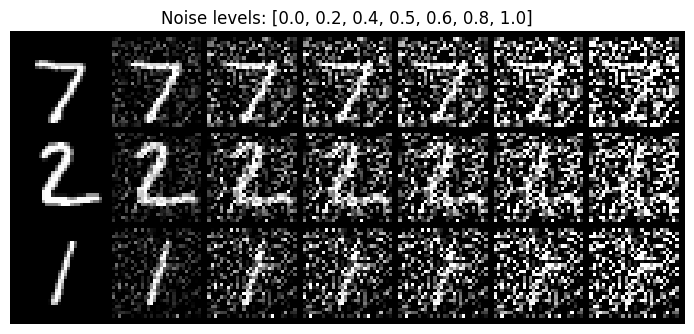

In [ ]:
# Visualize images at different noisy level
# ===== your code here! ====
clean = test_dataset.data[:3, None].float() / 255
noise = torch.randn(clean.shape, generator=torch.Generator().manual_seed(SEED))
sigmas = [0., .2, .4, .5, .6, .8, 1.]
noisy = torch.stack([image + sigma * eps for image, eps in zip(clean, noise) for sigma in sigmas])
show_grid(noisy, f'Noise levels: {sigmas}', 'noising.png', nrow=7)
# ===== end of code ====


## Part 1.2.1: Training

For this part, we provide some structure code for training. It is very basic, so feel free to change them or add your code. In later section we won't provide any training or visualization structure code.

In [ ]:
# Complete the recommended denoising hyperparameters from Section 1.2.1.
batch_size = 256
learning_rate = 1e-4
noise_level = .5
hidden_dim = 128
num_epochs = 5


In [ ]:
# MNIST train_dataset/test_dataset were loaded in setup.
# Build shuffled training and non-shuffled test DataLoaders.
train_loader = make_loader(batch_size)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)


In [ ]:
# Define your model, optimizer, and loss
# ===== your code here! ====
torch.manual_seed(SEED)
model = UnconditionalUNet(1, hidden_dim).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
criterion = nn.MSELoss()
denoise_dir = OUT / 'denoise'
denoise_dir.mkdir(exist_ok=True)
clean = test_dataset.data[:10, None].float() / 255
noisy = clean + noise_level * torch.randn(clean.shape, generator=torch.Generator().manual_seed(181))
# ===== end of code ====


  0%|          | 0/235 [00:00<?, ?it/s]

Epoch 1: 0.0205


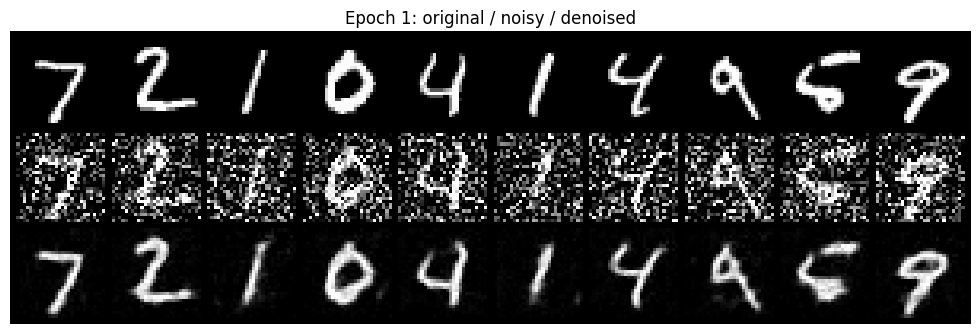

  0%|          | 0/235 [00:00<?, ?it/s]

Epoch 2: 0.0108


  0%|          | 0/235 [00:00<?, ?it/s]

Epoch 3: 0.0093


  0%|          | 0/235 [00:00<?, ?it/s]

Epoch 4: 0.0086


  0%|          | 0/235 [00:00<?, ?it/s]

Epoch 5: 0.0082


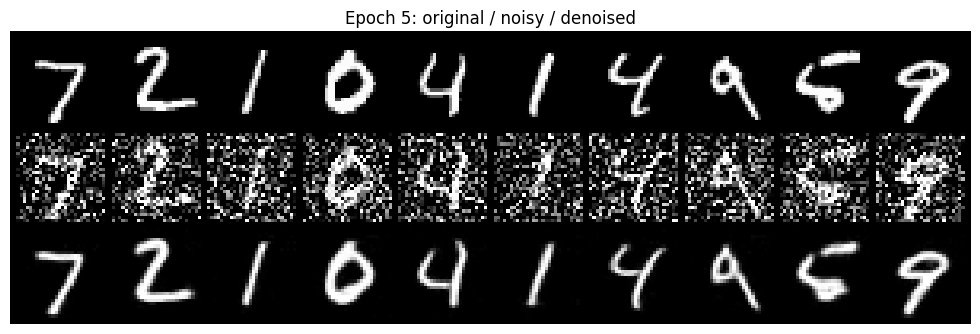

In [ ]:
# The training loops
train_losses = []
for epoch in range(num_epochs):
    model.train()
    for i, (images, _) in enumerate(tqdm(train_loader)):

        # ===== your code here! ====

        images = images.to(device)
        outputs = model(images + noise_level * torch.randn_like(images))

        # ===== end of code ====

        loss = criterion(outputs, images)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_losses.append(loss.item())
    print(f'Epoch {epoch + 1}: {sum(train_losses[-len(train_loader):]) / len(train_loader):.4f}')
    torch.save({'model': model.state_dict(), 'optimizer': optimizer.state_dict(),
                'epoch': epoch + 1, 'losses': train_losses}, denoise_dir / 'latest.pt')
    if epoch + 1 in (1, 5):
        model.eval()
        with torch.inference_mode():
            result = model(noisy.to(device)).cpu()
        show_grid(torch.cat((clean, noisy, result)),
                  f'Epoch {epoch + 1}: original / noisy / denoised',
                  f'denoise/epoch_{epoch + 1}.png')


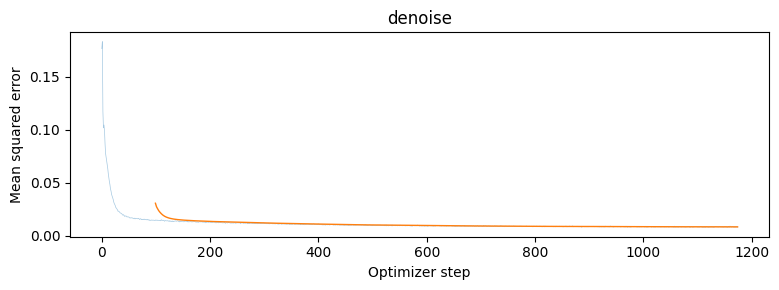

In [ ]:
# Visualize your training curve
# ===== your code here! ====
loss_plot(train_losses, 'denoise')
# ===== end of code ====


## Part 1.2.2: Out-of-Distribution Testing

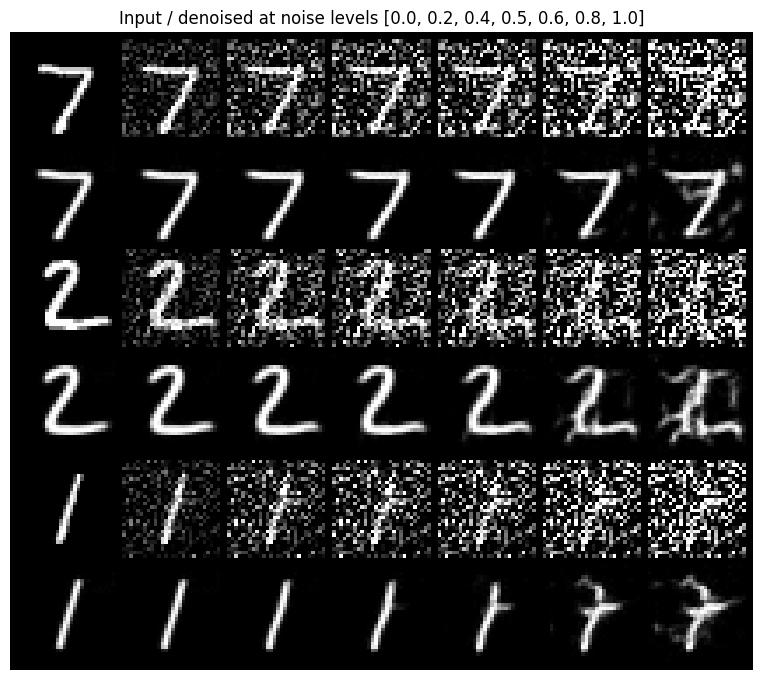

In [ ]:
# Visualize OOD testing
# ===== your code here! ====
model.eval()
clean = test_dataset.data[:3, None].float() / 255
noise = torch.randn(clean.shape, generator=torch.Generator().manual_seed(SEED))
images = []
with torch.inference_mode():
    for image, eps in zip(clean, noise):
        noisy = torch.stack([image + sigma * eps for sigma in sigmas])
        images.extend(noisy)
        images.extend(model(noisy.to(device)).cpu())
show_grid(torch.stack(images), f'Input / denoised at noise levels {sigmas}', 'ood.png', nrow=7)
# ===== end of code ====


## Part 1.2.3 Denoising Pure Noise

  0%|          | 0/235 [00:00<?, ?it/s]

Epoch 1: 0.0732


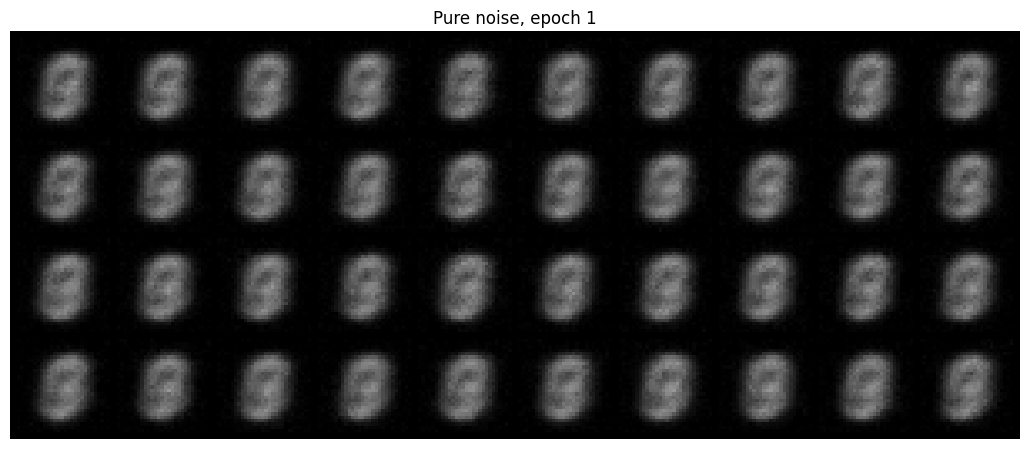

  0%|          | 0/235 [00:00<?, ?it/s]

Epoch 2: 0.0675


  0%|          | 0/235 [00:00<?, ?it/s]

Epoch 3: 0.0675


  0%|          | 0/235 [00:00<?, ?it/s]

Epoch 4: 0.0674


  0%|          | 0/235 [00:00<?, ?it/s]

Epoch 5: 0.0674


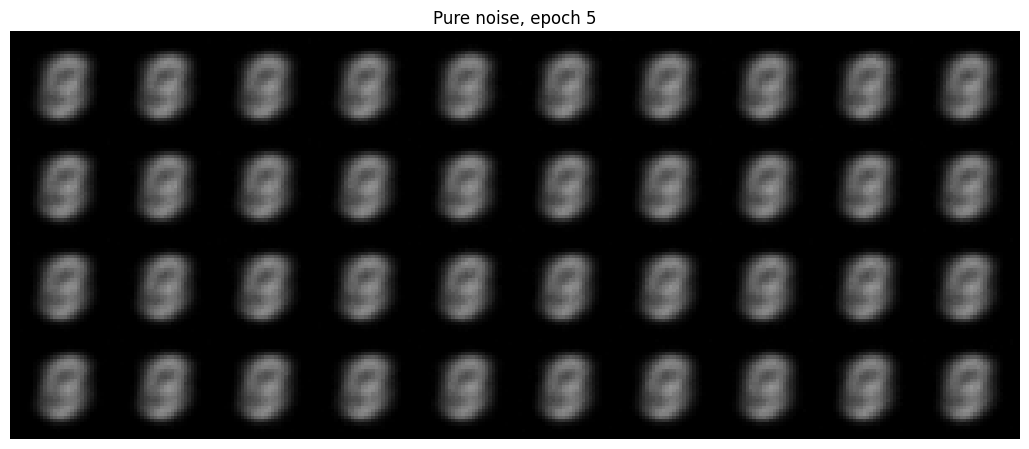

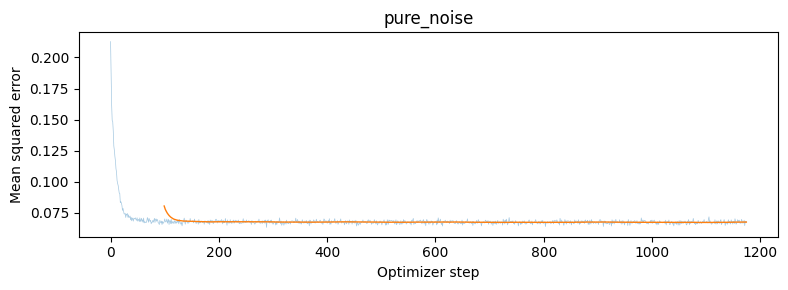

In [ ]:
# Section 1.2.3: train a fresh D=128 UNet for 5 epochs, Adam lr=1e-4,
# batch size 256. Input is independent Gaussian noise, target is a clean digit.
# Plot losses, show held-out results at epochs 1 and 5, and explain averaging.

torch.manual_seed(SEED)
pure_model = UnconditionalUNet(1, 128).to(device)
pure_optimizer = torch.optim.Adam(pure_model.parameters(), lr=1e-4)
pure_loader = make_loader(256)
pure_dir = OUT / 'pure_noise'
pure_dir.mkdir(exist_ok=True)
pure_losses = []
fixed_noise = torch.randn(40, 1, 28, 28, generator=torch.Generator().manual_seed(181)).to(device)
for epoch in range(5):
    pure_model.train()
    for images, _ in tqdm(pure_loader):
        images = images.to(device)
        loss = F.mse_loss(pure_model(torch.randn_like(images)), images)
        pure_optimizer.zero_grad()
        loss.backward()
        pure_optimizer.step()
        pure_losses.append(loss.item())
    print(f'Epoch {epoch + 1}: {sum(pure_losses[-len(pure_loader):]) / len(pure_loader):.4f}')
    torch.save({'model': pure_model.state_dict(), 'optimizer': pure_optimizer.state_dict(),
                'epoch': epoch + 1, 'losses': pure_losses}, pure_dir / 'latest.pt')
    if epoch + 1 in (1, 5):
        pure_model.eval()
        with torch.inference_mode():
            result = pure_model(fixed_noise).cpu()
        show_grid(result, f'Pure noise, epoch {epoch + 1}', f'pure_noise/epoch_{epoch + 1}.png')
loss_plot(pure_losses, 'pure_noise')
# Independent noise contains no information about the target digit.
# Under MSE, the model learns the average digit, giving similar blurry outputs.


# Part 2: Flow Matching

# Part 2.1: Implementing a Time-conditioned UNet

In [ ]:
class FCBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.layers = nn.Sequential(nn.Linear(in_channels, out_channels), nn.GELU(),
                                    nn.Linear(out_channels, out_channels))
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.layers(x)
        # ===== end of code ====


class TimeConditionalUNet(nn.Module):
    def __init__(
        self,
        in_channels: int,
        num_classes: int,
        num_hiddens: int,
    ):
        super().__init__()
        # ===== your code here! ====
        d = num_hiddens
        self.conv = ConvBlock(in_channels, d)
        self.down1 = DownBlock(d, d)
        self.down2 = DownBlock(d, 2 * d)
        self.flatten = Flatten()
        self.unflatten = Unflatten(2 * d)
        self.up1 = UpBlock(4 * d, d)
        self.up2 = UpBlock(2 * d, d)
        self.out = nn.Sequential(ConvBlock(2 * d, d), nn.Conv2d(d, in_channels, 3, 1, 1))
        self.fc1_t = FCBlock(1, 2 * num_hiddens)
        self.fc2_t = FCBlock(1, num_hiddens)
        # ===== end of code ====

    def forward(
        self,
        x: torch.Tensor,
        t: torch.Tensor,
    ) -> torch.Tensor:
        """
        Args:
            x: (N, C, H, W) input tensor.
            t: (N,) normalized time tensor.

        Returns:
            (N, C, H, W) output tensor.
        """
        assert x.shape[-2:] == (28, 28), "Expect input shape to be (28, 28)."
        # ===== your code here! ====
        t = t.reshape(-1, 1).to(x)
        t1 = self.fc1_t(t)[:, :, None, None]
        t2 = self.fc2_t(t)[:, :, None, None]
        x1 = self.conv(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.unflatten(self.flatten(x3)) * t1
        x5 = self.up1(torch.cat((x4, x3), dim=1)) * t2
        x6 = self.up2(torch.cat((x5, x2), dim=1))
        return self.out(torch.cat((x6, x1), dim=1))
        # ===== end of code ====


## Implementing the Forward and Reverse Process for Time-conditioned Denoising

In [ ]:
def time_fm_forward(
    unet: TimeConditionalUNet,
    x_1: torch.Tensor,
    num_ts: int,
) -> torch.Tensor:
    """Algorithm 1

    Args:
        unet: TimeConditionalUNet
        x_1: (N, C, H, W) input tensor.
        num_ts: int, number of timesteps.
    Returns:
        (,) loss.
    """
    unet.train()
    x_0 = torch.randn_like(x_1)
    t = torch.rand(len(x_1), device=x_1.device)
    t_img = t[:, None, None, None]
    x_t = (1 - t_img) * x_0 + t_img * x_1
    return F.mse_loss(unet(x_t, t), x_1 - x_0)


In [ ]:
@torch.inference_mode()
def time_fm_sample(
    unet: TimeConditionalUNet,
    img_wh: tuple[int, int],
    num_ts: int,
    seed: int = 0,
) -> torch.Tensor:
    """Algorithm 2

    Args:
        unet: TimeConditionalUNet
        img_wh: (H, W) output image width and height.
        num_ts: int, number of timesteps.
        seed: int, random seed.

    Returns:
        (N, C, H, W) final sample.
    """
    unet.eval()
    device = next(unet.parameters()).device
    # CPU generator makes the initial noise reproducible across devices.
    gen = torch.Generator().manual_seed(seed)
    x = torch.randn(40, 1, *img_wh, generator=gen).to(device)
    for i in range(num_ts):
        t = torch.full((len(x),), i / num_ts, device=device)
        x = x + unet(x, t) / num_ts
    return x


In [ ]:
class TimeConditionalFM(nn.Module):
    def __init__(
        self,
        unet: TimeConditionalUNet,
        num_ts: int = 50,
        img_hw: tuple[int, int] = (28, 28),
    ):
        super().__init__()

        self.unet = unet
        self.num_ts = num_ts
        self.img_hw = img_hw


    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: (N, C, H, W) input tensor.

        Returns:
            (,) flow-matching loss.
        """
        return time_fm_forward(
            self.unet, x, self.num_ts
        )


    @torch.inference_mode()
    def sample(
        self,
        img_wh: tuple[int, int],
        seed: int = 0,
    ):
        return time_fm_sample(
            self.unet, img_wh, self.num_ts, seed
        )

# Part 2.2: Training the Time-conditioned UNet

  0%|          | 0/938 [00:00<?, ?it/s]

Epoch 1: 0.1767


  0%|          | 0/938 [00:00<?, ?it/s]

Epoch 2: 0.1203


  0%|          | 0/938 [00:00<?, ?it/s]

...

Epoch 8: 0.0941


  0%|          | 0/938 [00:00<?, ?it/s]

Epoch 9: 0.0928


  0%|          | 0/938 [00:00<?, ?it/s]

Epoch 10: 0.0917


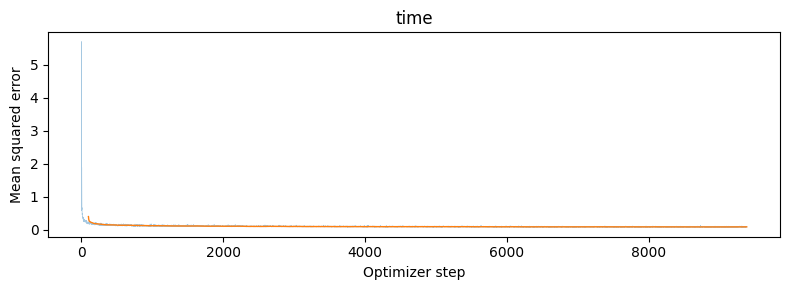

In [ ]:
# Feel free to use code from part 1.2.1
# as they should be very similar
# ===== your code here! ====


torch.manual_seed(SEED)
time_model = TimeConditionalUNet(1, 10, 64).to(device)
time_fm = TimeConditionalFM(time_model, num_ts=50)
time_optimizer = torch.optim.Adam(time_model.parameters(), lr=1e-2)
time_scheduler = torch.optim.lr_scheduler.ExponentialLR(time_optimizer, gamma=.1 ** (1 / 10))
time_loader = make_loader(64)
time_dir = OUT / 'time'
time_dir.mkdir(exist_ok=True)
time_losses = []
for epoch in range(10):
    for images, _ in tqdm(time_loader):
        loss = time_fm(images.to(device))
        time_optimizer.zero_grad()
        loss.backward()
        time_optimizer.step()
        time_losses.append(loss.item())
    time_scheduler.step()
    print(f'Epoch {epoch + 1}: {sum(time_losses[-len(time_loader):]) / len(time_loader):.4f}')
    checkpoint = {'model': time_model.state_dict(), 'optimizer': time_optimizer.state_dict(),
                  'scheduler': time_scheduler.state_dict(), 'epoch': epoch + 1, 'losses': time_losses}
    torch.save(checkpoint, time_dir / 'latest.pt')
    if epoch + 1 in (1, 5, 10):
        torch.save(checkpoint, time_dir / f'epoch_{epoch + 1}.pt')
loss_plot(time_losses, 'time')
# ===== end of code ====


# Part 2.3: Sampling from the Time-conditioned UNet

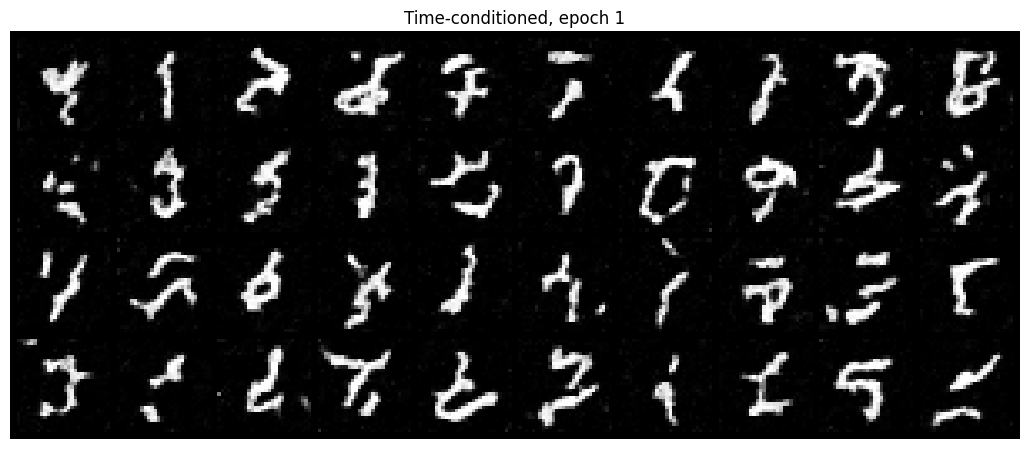

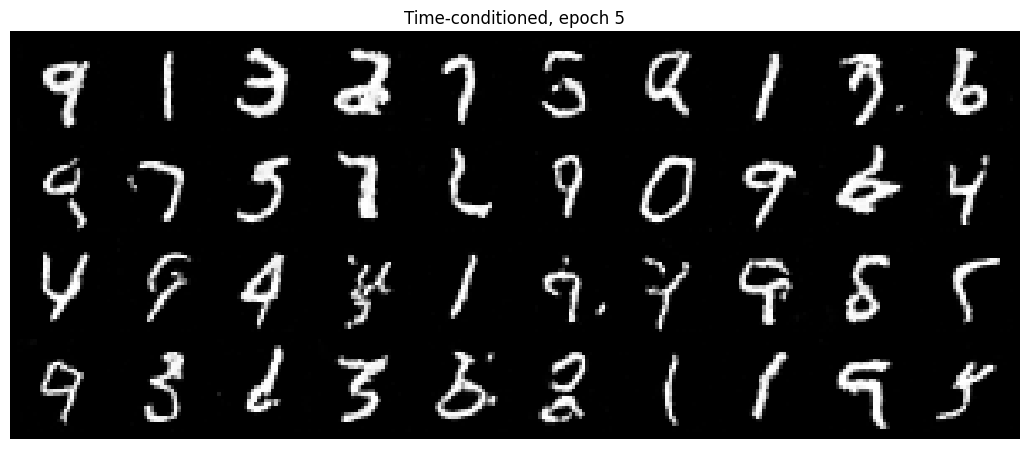

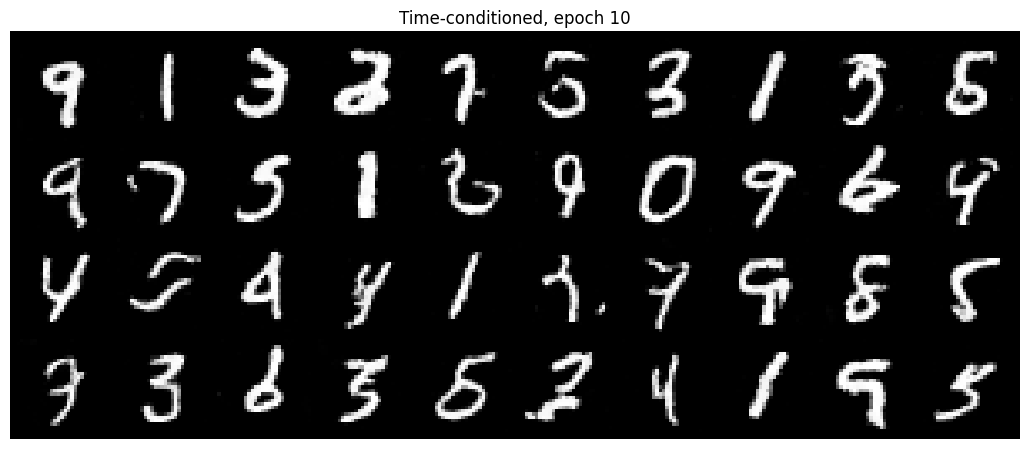

In [ ]:
# Sampling from the UNet
# ===== your code here! ====


for epoch in (1, 5, 10):
    checkpoint = torch.load(time_dir / f'epoch_{epoch}.pt', map_location=device, weights_only=True)
    time_model.load_state_dict(checkpoint['model'])
    samples = time_fm.sample((28, 28), seed=SEED)
    show_grid(samples, f'Time-conditioned, epoch {epoch}', f'time/epoch_{epoch}.png')
# ===== end of code ====


# Part 2.4: Implementing a Class-conditioned UNet

In [ ]:
class ClassConditionalUNet(nn.Module):
    def __init__(
        self,
        in_channels: int,
        num_classes: int,
        num_hiddens: int,
    ):
        super().__init__()
        # ===== your code here! ====
        d = num_hiddens
        self.conv = ConvBlock(in_channels, d)
        self.down1 = DownBlock(d, d)
        self.down2 = DownBlock(d, 2 * d)
        self.flatten = Flatten()
        self.unflatten = Unflatten(2 * d)
        self.up1 = UpBlock(4 * d, d)
        self.up2 = UpBlock(2 * d, d)
        self.out = nn.Sequential(ConvBlock(2 * d, d), nn.Conv2d(d, in_channels, 3, 1, 1))
        self.fc1_t = FCBlock(1, 2 * num_hiddens)
        self.fc2_t = FCBlock(1, num_hiddens)
        self.num_classes = num_classes
        self.fc1_c = FCBlock(num_classes, 2 * num_hiddens)
        self.fc2_c = FCBlock(num_classes, num_hiddens)
        # ===== end of code ====

    def forward(
        self,
        x: torch.Tensor,
        c: torch.Tensor,
        t: torch.Tensor,
        mask: Optional[torch.Tensor] = None,
    ) -> torch.Tensor:
        """
        Args:
            x: (N, C, H, W) input tensor.
            c: (N,) int64 condition tensor.
            t: (N,) normalized time tensor.
            mask: (N,) mask tensor. If not None, mask out condition when mask == 0.

        Returns:
            (N, C, H, W) output tensor.
        """
        assert x.shape[-2:] == (28, 28), "Expect input shape to be (28, 28)."
        # ===== your code here! ====
        t = t.reshape(-1, 1).to(x)
        c = F.one_hot(c.long(), self.num_classes).to(x)
        if mask is not None:
            c = c * mask.reshape(-1, 1).to(x)
        t1 = self.fc1_t(t)[:, :, None, None]
        t2 = self.fc2_t(t)[:, :, None, None]
        c1 = self.fc1_c(c)[:, :, None, None]
        c2 = self.fc2_c(c)[:, :, None, None]
        x1 = self.conv(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = c1 * self.unflatten(self.flatten(x3)) + t1
        x5 = c2 * self.up1(torch.cat((x4, x3), dim=1)) + t2
        x6 = self.up2(torch.cat((x5, x2), dim=1))
        return self.out(torch.cat((x6, x1), dim=1))
        # ===== end of code ====


In [ ]:
def class_fm_forward(
    unet: ClassConditionalUNet,
    x_1: torch.Tensor,
    c: torch.Tensor,
    p_uncond: float,
    num_ts: int,
) -> torch.Tensor:
    """Algorithm 3

    Args:
        unet: ClassConditionalUNet
        x_1: (N, C, H, W) input tensor.
        c: (N,) int64 condition tensor.
        p_uncond: float, probability of unconditioning the condition.
        num_ts: int, number of timesteps.

    Returns:
        (,) loss.
    """
    unet.train()
    x_0 = torch.randn_like(x_1)
    t = torch.rand(len(x_1), device=x_1.device)
    t_img = t[:, None, None, None]
    x_t = (1 - t_img) * x_0 + t_img * x_1
    mask = (torch.rand(len(x_1), device=x_1.device) >= p_uncond).float()
    return F.mse_loss(unet(x_t, c, t, mask), x_1 - x_0)


In [ ]:
@torch.inference_mode()
def class_fm_sample(
    unet: ClassConditionalUNet,
    c: torch.Tensor,
    img_wh: tuple[int, int],
    num_ts: int,
    guidance_scale: float = 5.0,
    seed: int = 0,
) -> torch.Tensor:
    """Algorithm 4

    Args:
        unet: ClassConditionalUNet
        c: (N,) int64 condition tensor. Only for class-conditional
        img_wh: (H, W) output image width and height.
        num_ts: int, number of timesteps.
        guidance_scale: float, CFG scale.
        seed: int, random seed.

    Returns:
        (N, C, H, W) final sample.
        (N, T_animation, C, H, W) caches.
    """
    unet.eval()
    device = next(unet.parameters()).device
    c = c.to(device)
    gen = torch.Generator().manual_seed(seed)
    x = torch.randn(len(c), 1, *img_wh, generator=gen).to(device)
    mask = torch.ones(len(c), device=device)
    states = [x.cpu().clone()]
    for i in range(num_ts):
        t = torch.full((len(x),), i / num_ts, device=device)
        vc = unet(x, c, t, mask)
        vu = unet(x, c, t, torch.zeros_like(mask))
        # Part B uses vu + gamma * (vc - vu), unlike Part A.
        x = x + (vu + guidance_scale * (vc - vu)) / num_ts
        if (i + 1) % max(1, num_ts // 10) == 0 or i == num_ts - 1:
            states.append(x.cpu().clone())
    return x, torch.stack(states, dim=1)


In [ ]:
class ClassConditionalFM(nn.Module):
    def __init__(
        self,
        unet: ClassConditionalUNet,
        num_ts: int = 300,
        p_uncond: float = 0.1,
    ):
        super().__init__()
        self.unet = unet
        self.num_ts = num_ts
        self.p_uncond = p_uncond

    def forward(self, x: torch.Tensor, c: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: (N, C, H, W) input tensor.
            c: (N,) int64 condition tensor.

        Returns:
            (,) loss.
        """
        return class_fm_forward(
            self.unet, x, c, self.p_uncond, self.num_ts
        )

    @torch.inference_mode()
    def sample(
        self,
        c: torch.Tensor,
        img_wh: tuple[int, int],
        guidance_scale: float = 5.0,
        seed: int = 0,
    ):
        return class_fm_sample(
            self.unet, c, img_wh, self.num_ts, guidance_scale, seed
        )

# Part 2.5 Training the Class-conditioned UNet

  0%|          | 0/938 [00:00<?, ?it/s]

class, epoch 1: 0.1739


  0%|          | 0/938 [00:00<?, ?it/s]

class, epoch 2: 0.1172


  0%|          | 0/938 [00:00<?, ?it/s]

...

class, epoch 8: 0.0875


  0%|          | 0/938 [00:00<?, ?it/s]

class, epoch 9: 0.0860


  0%|          | 0/938 [00:00<?, ?it/s]

class, epoch 10: 0.0850


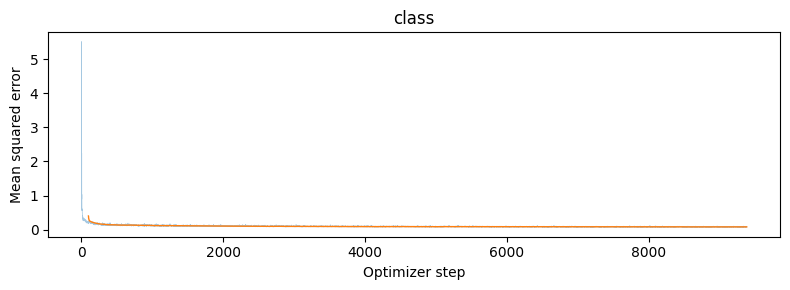

  0%|          | 0/938 [00:00<?, ?it/s]

no_scheduler, epoch 1: 0.1367


  0%|          | 0/938 [00:00<?, ?it/s]

no_scheduler, epoch 2: 0.1037


  0%|          | 0/938 [00:00<?, ?it/s]

...

no_scheduler, epoch 8: 0.0864


  0%|          | 0/938 [00:00<?, ?it/s]

no_scheduler, epoch 9: 0.0854


  0%|          | 0/938 [00:00<?, ?it/s]

no_scheduler, epoch 10: 0.0846


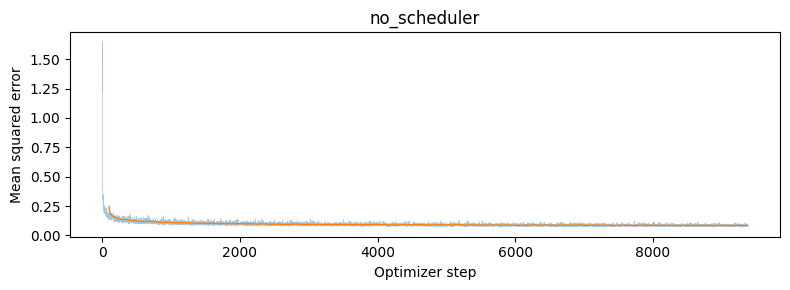

In [ ]:
# Train a fresh class-conditioned D=64 UNet for 10 epochs, batch size 64,
# Adam initial lr=1e-2, class dropout probability .1, exponential gamma=.1**(1/10).
# Save checkpoints at epochs 1,5,10. Then train an independent no-scheduler
# comparison; choose/document a constant learning rate and compare results.

class_models = {}
class_losses = {}
for name, lr in [('class', 1e-2), ('no_scheduler', 1e-3)]:
    torch.manual_seed(SEED)
    class_model = ClassConditionalUNet(1, 10, 64).to(device)
    class_fm = ClassConditionalFM(class_model, num_ts=300, p_uncond=.1)
    optimizer = torch.optim.Adam(class_model.parameters(), lr=lr)
    scheduler = None
    if name == 'class':
        scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=.1 ** (1 / 10))
    loader = make_loader(64)
    folder = OUT / name
    folder.mkdir(exist_ok=True)
    losses = []
    for epoch in range(10):
        for images, labels in tqdm(loader):
            loss = class_fm(images.to(device), labels.to(device))
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            losses.append(loss.item())
        if scheduler is not None:
            scheduler.step()
        print(f'{name}, epoch {epoch + 1}: {sum(losses[-len(loader):]) / len(loader):.4f}')
        checkpoint = {'model': class_model.state_dict(), 'optimizer': optimizer.state_dict(),
                      'scheduler': scheduler.state_dict() if scheduler else None,
                      'epoch': epoch + 1, 'losses': losses}
        torch.save(checkpoint, folder / 'latest.pt')
        if epoch + 1 in (1, 5, 10):
            torch.save(checkpoint, folder / f'epoch_{epoch + 1}.pt')
    class_models[name] = class_model
    class_losses[name] = losses
    loss_plot(losses, name)


# Part 2.6: Sampling from the Class-conditioned UNet

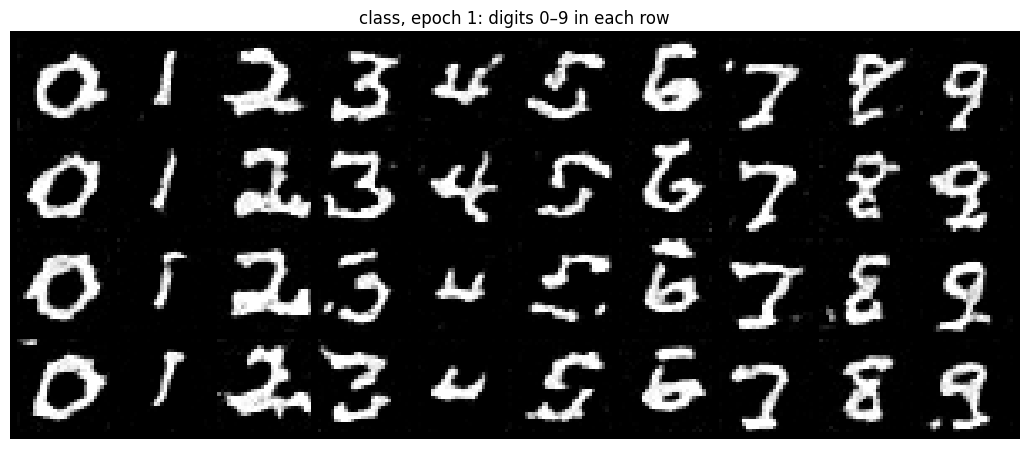

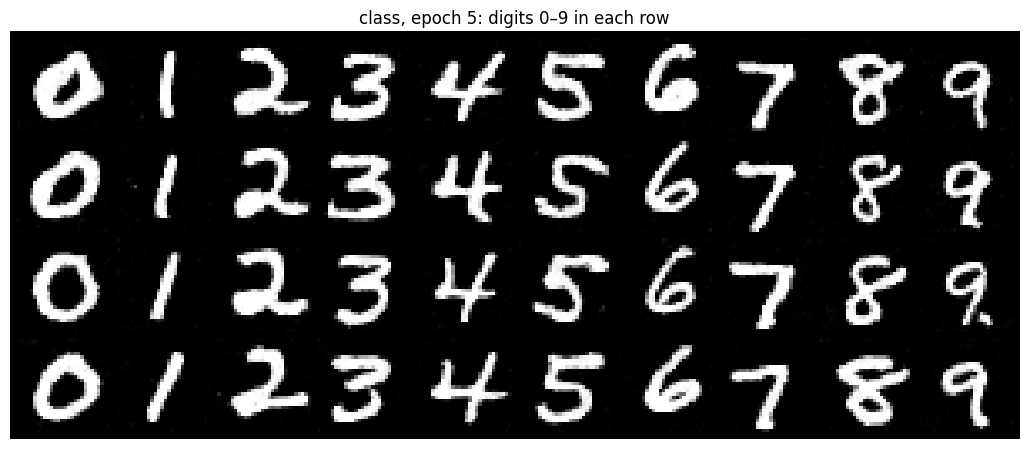

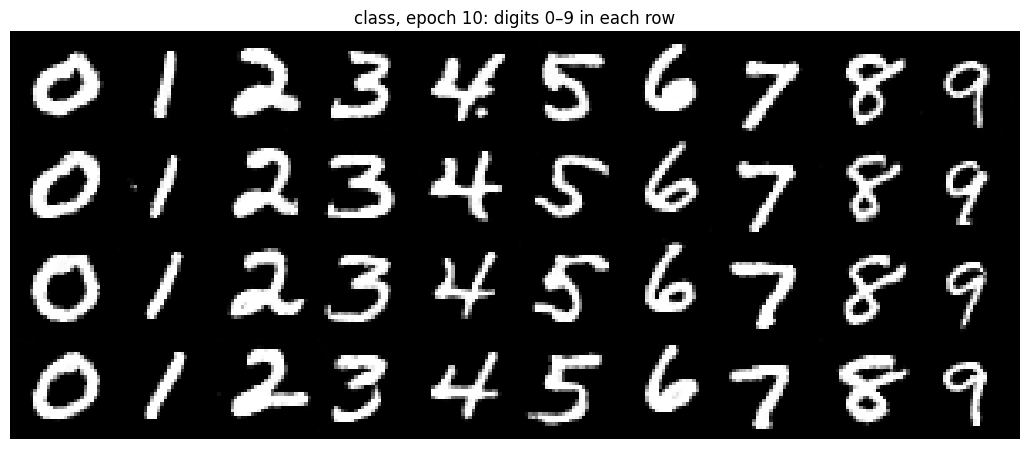

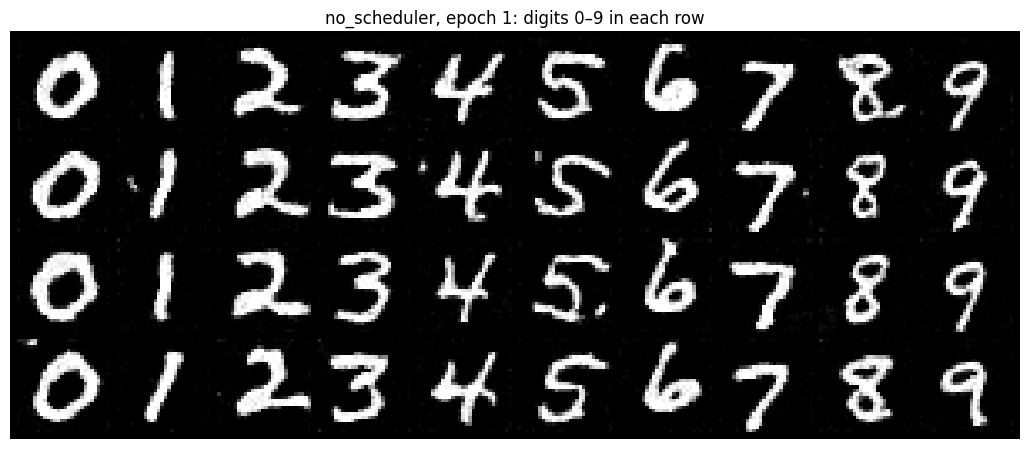

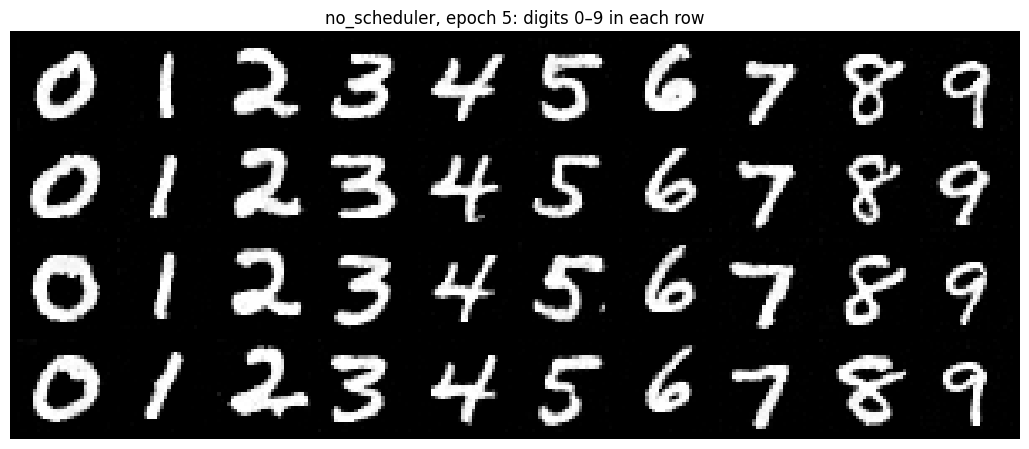

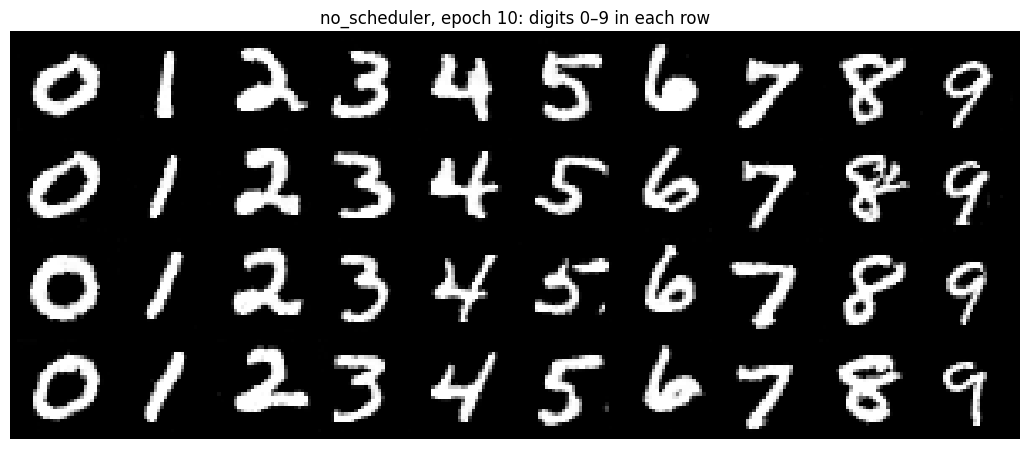

In [ ]:
# At epochs 1,5,10, generate four instances of each digit (40 images),
# with 300 Euler steps and guidance scale 5.0. Keep seeds fixed for comparisons.
# Also visualize the no-scheduler model and describe the tradeoff.

labels = torch.arange(10).repeat(4).to(device)
for name, class_model in class_models.items():
    for epoch in (1, 5, 10):
        checkpoint = torch.load(OUT / name / f'epoch_{epoch}.pt', map_location=device, weights_only=True)
        class_model.load_state_dict(checkpoint['model'])
        samples, states = class_fm_sample(class_model, labels, (28, 28), 300, 5., SEED)
        show_grid(samples, f'{name}, epoch {epoch}: digits 0–9 in each row',
                  f'{name}/epoch_{epoch}.png')
        torch.save(states, OUT / name / f'epoch_{epoch}_trajectory.pt')
# The fixed 1e-3 learning rate also produces recognizable digits by epoch 10.
# The scheduler permits a larger initial learning rate and smaller updates later.
